# Random submission
## STEP 1 : Install and import libraries

In [ ]:
! pip install scikit-image
! pip install matplotlib
! pip install numpy
! pip install pandas

In [ ]:
import os
import numpy as np
import pandas as pd
from pathlib import Path
from skimage import io
import matplotlib.pyplot as plt
from PIL import Image


## STEP 2 : Import and parse the data

For this step, you will download the dataset from kaggle as a zip file


Hint : The data in kaggle can be downloaded from the data tab in the following place :

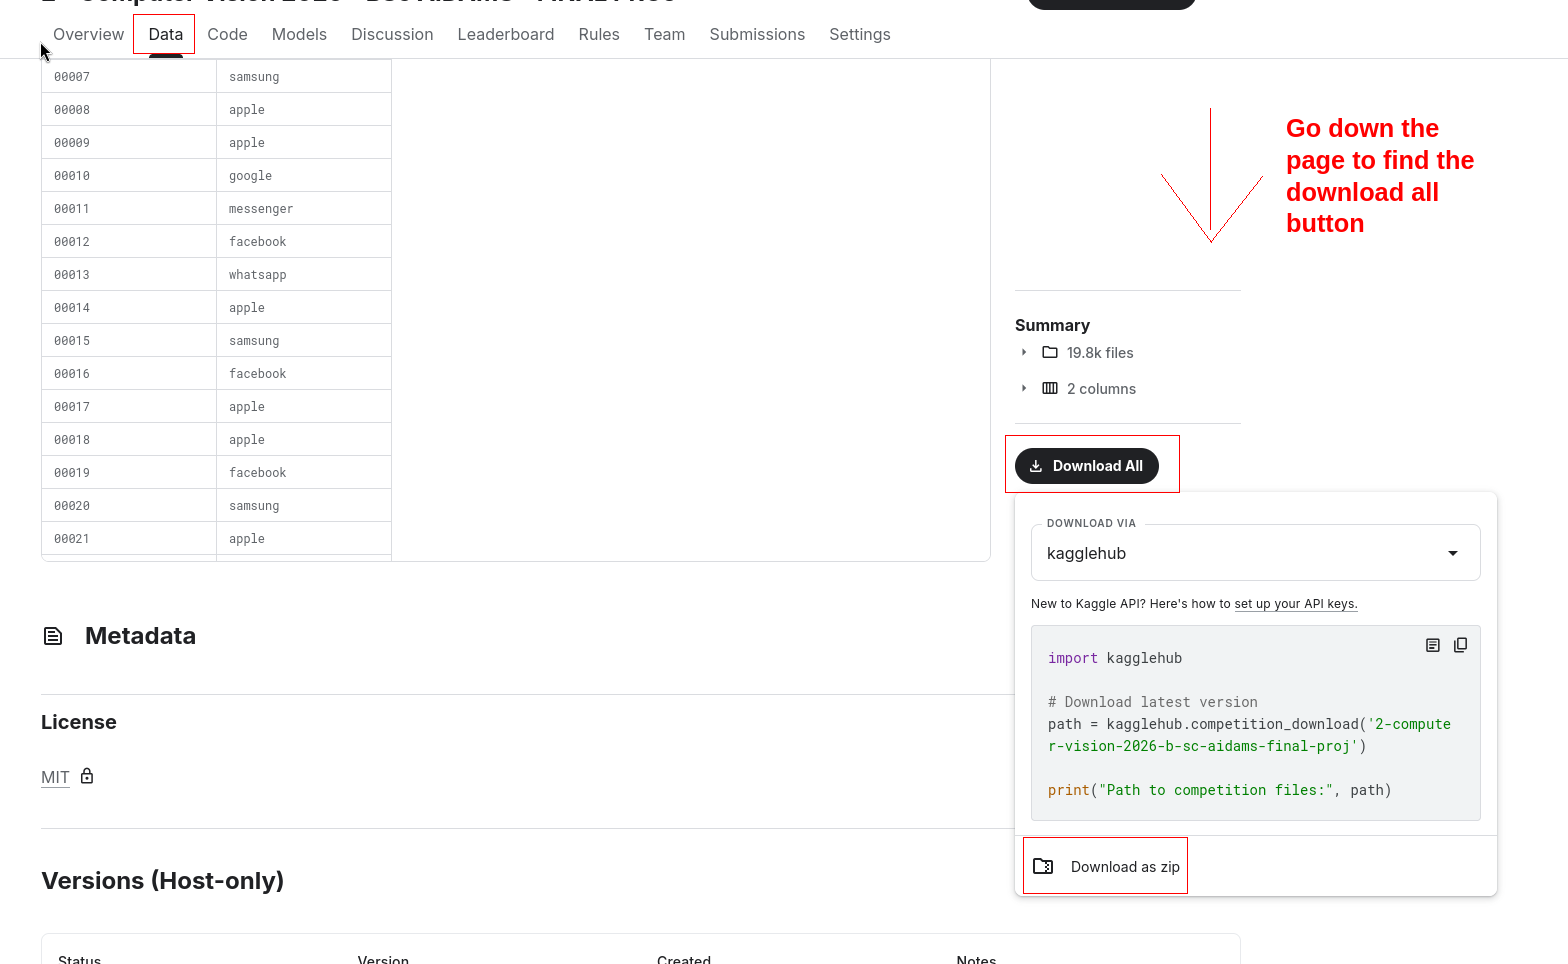

Then drop it in the default folder of google collab (This folder is /content, to check where you currently are, use the next command and check that it replies /content)

In [ ]:
! pwd

Run the following command to see the train / test dataset appear, as well as the train labels

In [ ]:
! unzip  "/content/2-computer-vision-2026-b-sc-aidams-final-proj.zip"

The following code will run through a dataset and show you the different files of the training dataset :

In [ ]:
for dirname, _, filenames in os.walk('/content/train'):
    for filename in filenames[:5]: # I print 5 files per folder
        print(os.path.join(dirname, filename))


### Function definition

In [ ]:
def show_img(imgs, titles, gray=False, length=None, array_of_array=False):
    """
    Input : - imgs : list of np.arrays of images (or one np.array)
            - titles : list of strings (or one string)

    Description : Plots the images in a row with their corresponding titles.
                  If one image : only plots one image.

    Returns : None
    """
    if not array_of_array:
        if type(imgs) != list:
            imgs = [imgs]
    if type(titles) != list:
        titles = [titles]

    if len(imgs) != len(titles):
        raise ValueError(
            f"""You provided {len(imgs)} images and {len(titles)} titles.
                         Please provide equal number of images and titles."""
        )
    nb_imgs = len(imgs)
    if length:
        plt.figure(figsize=(length, 6))
    else:
        plt.figure()
    for i, (img, title) in enumerate(zip(imgs, titles)):
        plt.subplot(1, nb_imgs, i + 1)
        if gray:
            plt.imshow(img, cmap="gray")
        else:
            plt.imshow(img)
        plt.title(title)
        plt.axis("off")
    plt.show()

In [ ]:
def load_data(folder_path:str):
    path_to_images = Path(folder_path)
    ids = []
    dataset = []

    for img_file in sorted(path_to_images.iterdir()):

        id_img = "".join(img_file.name.split(".")[:-1])
        ids.append(id_img)

        # THIS IS THE DEFAULT LOADING, YOU CAN MODIFY OR CHANGE IT IF NEEDED (RGBA, MODE, ETC)

        img = io.imread(img_file)
        dataset.append(img)

    dataset_as_array = np.array(dataset)

    return dataset_as_array, ids

##  STEP 3 : Data Analysis
### Getting the shapes

This cell will return an error at first : it is normal, the preprocessing given as an example is incorrect on the cell above. It is part of the challenge to find the correct pre processing and loading of the data for the model as it has an impact on the performance.

In [ ]:
X_train, X_train_ids = load_data("/content/train")
print("Shape of train dataset", X_train.shape)

X_test, X_test_ids = load_data("/content/test")
print("Shape of test dataset", X_test.shape)

y_train = pd.read_csv("/content/train_labels.csv")
print("Shape of predictions for train dataset", y_train.shape)

### Showing example observations

In [ ]:
X_train_ids[:3]

In [ ]:
y_train.head(3)

In [ ]:
number_of_images_to_display = 10
selected_titles = [f"ID: {img_id}\nTrue value: {img_label}" for img_id, img_label in zip(X_train_ids, y_train["Label"])][:number_of_images_to_display]
selected_imgs = X_train[:number_of_images_to_display]
selected_imgs.shape

In [ ]:
show_img(selected_imgs,selected_titles, array_of_array=True, gray=True, length=15)


## STEP 4 : Train a model on the training dataset

In [ ]:
# TO FILL

## STEP 5 : Make predictions (random ones)

In [ ]:
def predict_with_my_amazing_model(X_test):
    # YOU NEED TO REPLACE THE MODEL HERE
    prediction = np.random.choice([0,1,2,3,4,5,6,7,8,9], size= len(X_test))
    ids = np.arange(1,len(X_test)+1)
    prediction_as_df = pd.DataFrame()
    return prediction

In [ ]:
y_test_pred = predict_with_my_amazing_model(X_test)

In [ ]:
y_test_pred

In [ ]:
X_test_ids_sr = pd.Series(X_test_ids, name="Id")
y_test_pred_sr = pd.Series(y_test_pred, name="Label")
submission_df = pd.concat([X_test_ids_sr, y_test_pred_sr], axis=1)

In [ ]:
submission_df.head()

In [ ]:
submission_df.to_csv("submission.csv", index=False)